# Обучение детектора архитектуры EAST

Пример для **Manuscript OCR 0.1.13**: обучим EAST находить **строки** на исторических рукописных страницах датасета [Riksarkivet/gota_hovratt_seg](https://huggingface.co/datasets/Riksarkivet/gota_hovratt_seg).

В датасете 51 страница шведских судебных документов. Изображения и PAGE XML с полигонами строк скачиваются из одного репозитория Hugging Face: четыре архива общим объёмом около 65 МБ. Для обучения детекции транскрипции не нужны.

## 1. Установка


In [ ]:
%pip install "manuscript-ocr[cpu,dev]==0.1.13" huggingface-hub

## 2. Загрузка данных

Скачаем изображения и PAGE XML из зафиксированной версии репозитория. Скрипт загрузчика датасета не используется.

Архивы содержат две группы документов, а не готовые разделы train/val. Ниже объединим их и выделим около 20% страниц для валидации с фиксированным seed.


In [1]:
from pathlib import Path
import json
import shutil
import tarfile
from huggingface_hub import hf_hub_download

DATA_DIR = Path("datasets/gota_hovratt_seg")
RAW_DIR = DATA_DIR / "raw"
REVISION = "cd9ae6e1079d6a89598ce6842646aacaa67ca461"

for folder, kind, suffix in (
    ("images", "images", ".jpg"),
    ("page_xmls", "page_xmls", ".xml"),
):
    destination = RAW_DIR / folder
    destination.mkdir(parents=True, exist_ok=True)
    for part in (1, 2):
        archive = hf_hub_download(
            repo_id="Riksarkivet/gota_hovratt_seg",
            repo_type="dataset",
            revision=REVISION,
            filename=f"data/{folder}/gota_hovratt_seg_{kind}_{part}.tar.gz",
            local_dir=DATA_DIR / "downloads",
        )
        # Копируем только нужные файлы, без вложенных путей из архива.
        with tarfile.open(archive, "r:gz") as tar:
            for member in tar:
                if member.isfile() and Path(member.name).suffix.lower() == suffix:
                    target = destination / Path(member.name).name
                    with tar.extractfile(member) as source, target.open("wb") as output:
                        shutil.copyfileobj(source, output)

print("Изображений:", len(list((RAW_DIR / "images").glob("*.jpg"))))
print("PAGE XML:", len(list((RAW_DIR / "page_xmls").glob("*.xml"))))


Изображений: 51
PAGE XML: 51


## 3. Подготовка и проверка разметки

Берём только `TextLine/Coords`: полигоны слов и текстовых блоков не попадут в обучение. Проверим размеры изображений и преобразуем разметку строк в COCO.

Разделяем данные по страницам: 41 для обучения и 10 для валидации. Это небольшое демонстрационное разбиение, а не официальный тестовый набор датасета.

EAST предсказывает четырёхугольники. При обучении полигоны строк будут преобразованы в повёрнутые прямоугольники через `quad_source="min_area_rect"`.


train: 41 страниц, 2194 строк
val: 10 страниц, 496 строк


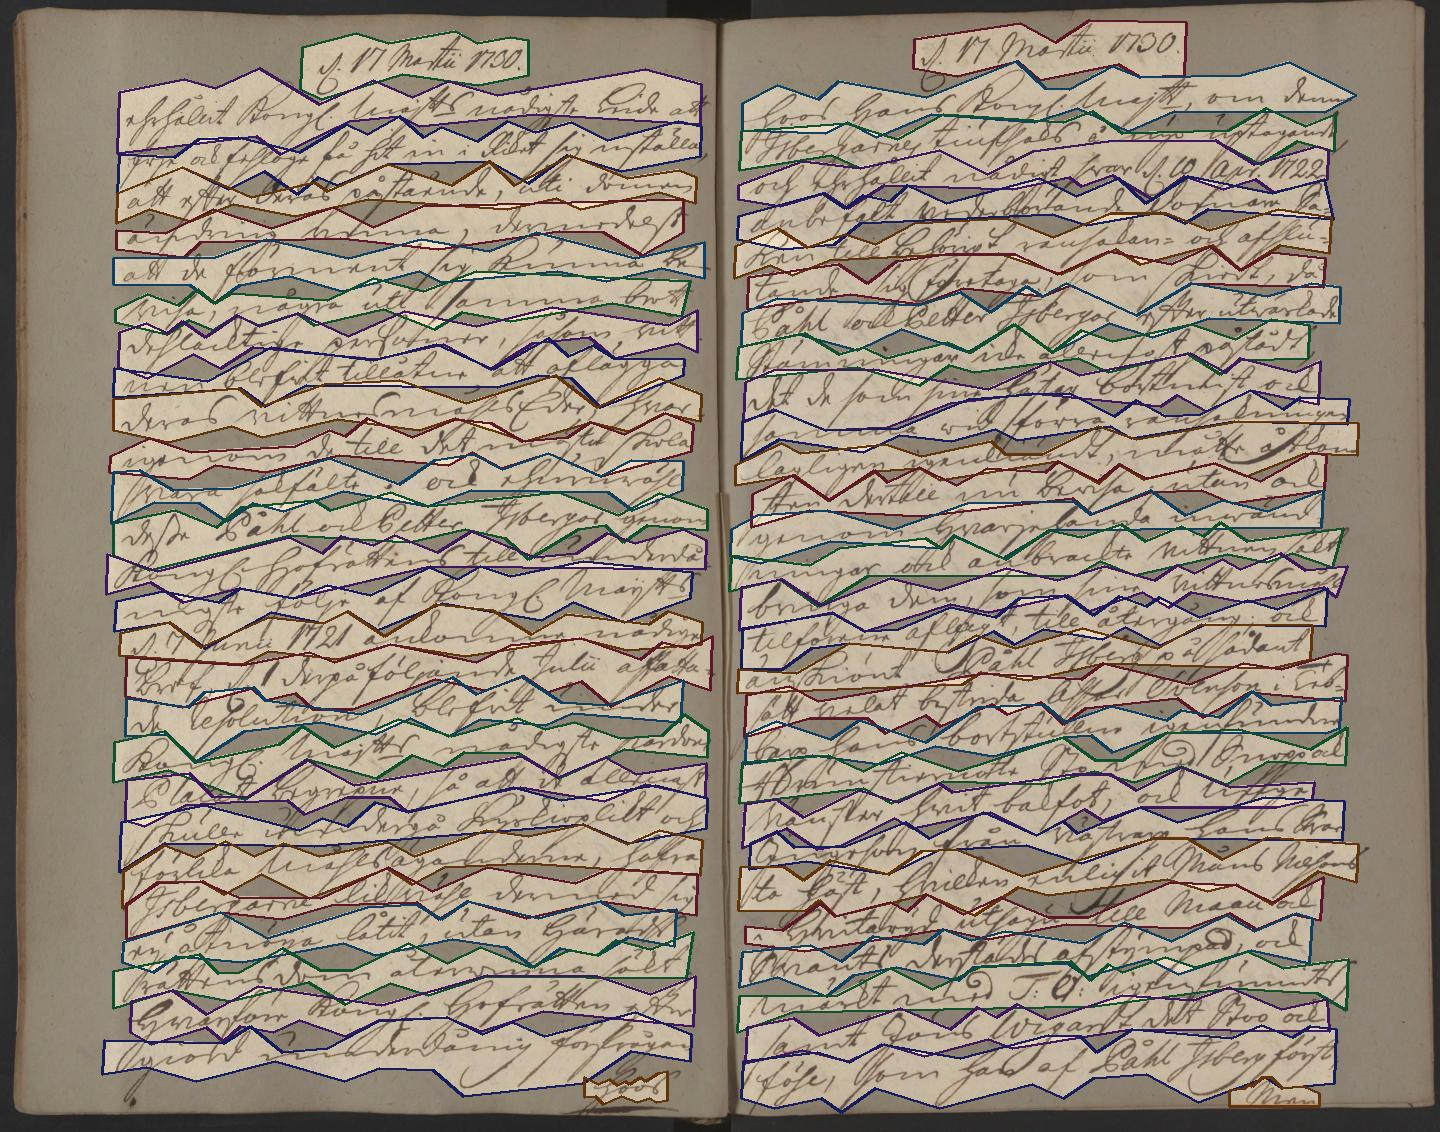

In [2]:
import random
import xml.etree.ElementTree as ET
from PIL import Image
from IPython.display import display
from manuscript.data import Page, TextRegion
from manuscript.utils import visualize_page

images_by_stem = {path.stem: path for path in (RAW_DIR / "images").glob("*.jpg")}
xml_paths = sorted((RAW_DIR / "page_xmls").glob("*.xml"))
assert {path.stem for path in xml_paths} == set(images_by_stem), "Не совпадают изображения и XML"
random.Random(42).shuffle(xml_paths)
val_count = max(1, round(len(xml_paths) * 0.2))
splits = {"train": xml_paths[val_count:], "val": xml_paths[:val_count]}
IMAGES_DIR = DATA_DIR / "images"

for split, paths in splits.items():
    destination = IMAGES_DIR / split
    destination.mkdir(parents=True, exist_ok=True)
    coco = {"images": [], "annotations": [], "categories": [{"id": 1, "name": "line"}]}
    for image_id, xml_path in enumerate(paths, start=1):
        page_xml = ET.parse(xml_path).getroot().find(".//{*}Page")
        source = images_by_stem[xml_path.stem]
        with Image.open(source) as original:
            width, height = original.size
        assert (width, height) == (int(page_xml.attrib["imageWidth"]), int(page_xml.attrib["imageHeight"])), source
        lines = []
        for line in page_xml.findall(".//{*}TextLine"):
            coords = line.find("{*}Coords")
            if coords is None:
                continue
            points = [tuple(map(float, pair.split(","))) for pair in coords.attrib["points"].split()]
            assert len(points) >= 3, xml_path
            assert all(0 <= x <= width and 0 <= y <= height for x, y in points), xml_path
            xs, ys = zip(*points)
            area = abs(sum(
                points[i][0] * points[(i + 1) % len(points)][1]
                - points[(i + 1) % len(points)][0] * points[i][1]
                for i in range(len(points))
            )) / 2
            assert area > 0, xml_path
            lines.append({
                "image_id": image_id, "category_id": 1,
                "segmentation": [[value for point in points for value in point]],
                "bbox": [min(xs), min(ys), max(xs) - min(xs), max(ys) - min(ys)],
                "area": area, "iscrowd": 0,
            })
        assert lines, f"Нет полигонов строк: {xml_path}"
        coco["images"].append({"id": image_id, "file_name": source.name, "width": width, "height": height})
        for annotation in lines:
            annotation["id"] = len(coco["annotations"]) + 1
            coco["annotations"].append(annotation)
        shutil.copy2(source, destination / source.name)
    (DATA_DIR / f"{split}_coco.json").write_text(json.dumps(coco, ensure_ascii=False), encoding="utf-8")
    print(f"{split}: {len(coco['images'])} страниц, {len(coco['annotations'])} строк")

# Посмотрим исходные полигоны строк до обучения.
sample = json.loads((DATA_DIR / "train_coco.json").read_text(encoding="utf-8"))
info = sample["images"][0]
image = Image.open(IMAGES_DIR / "train" / info["file_name"]).convert("RGB")
page = Page(image_width=image.width, image_height=image.height)
for annotation in sample["annotations"]:
    if annotation["image_id"] == info["id"]:
        coords = annotation["segmentation"][0]
        region = TextRegion(type="line", polygon=list(zip(coords[::2], coords[1::2])))
        region.parent = page
display(visualize_page(image, page, numbers_levels=[], max_size=1440, upscale=True))


## 4. Обучение

Одна эпоха позволяет проверить весь процесс; для обучения полезной модели увеличьте `EPOCHS` и следите за метриками валидации. Рекомендуется GPU: в Colab выберите среду выполнения с GPU.

`target_size=1024` сохраняет больше деталей длинных строк, чем 512. `detection_level="line"` записывает в конфиг тип выдаваемых регионов; сами строки заданы полигонами в COCO.


In [ ]:
import torch
from manuscript.detectors import EAST

EXP_ROOT = Path("experiments")
MODEL_NAME = "east_gota_hovratt_lines"
EXP_DIR = EXP_ROOT / MODEL_NAME
EPOCHS = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EAST.train(
    train_images=str(IMAGES_DIR / "train"),
    train_anns=str(DATA_DIR / "train_coco.json"),
    val_images=str(IMAGES_DIR / "val"),
    val_anns=str(DATA_DIR / "val_coco.json"),
    experiment_root=str(EXP_ROOT),
    model_name=MODEL_NAME,
    backbone_name="resnet50",
    pretrained_backbone=True,
    target_size=1024,
    epochs=EPOCHS,
    batch_size=1,
    num_workers=0,
    use_multiscale=False,
    augmentation_config={"quad_source": "min_area_rect"},
    detection_level="line",
    device=DEVICE,
)

## 5. Артефакты и загрузка модели

После обучения выполняется экспорт в ONNX. Для своего детектора нужны **два файла**: `checkpoints/best_model.onnx` и `checkpoints/best_model.json`. Веса PyTorch и состояние обучения нужны для продолжения обучения или повторного экспорта; `training_config.json` описывает параметры эксперимента.


In [4]:
import os

for directory, _, filenames in os.walk(EXP_DIR):
    for filename in sorted(filenames):
        path = Path(directory) / filename
        print(path.relative_to(EXP_DIR), f"({path.stat().st_size / 1024:.1f} КБ)")

# Передаём оба обязательных артефакта явно.
detector = EAST(
    weights=str(EXP_DIR / "checkpoints/best_model.onnx"),
    config=str(EXP_DIR / "checkpoints/best_model.json"),
    device="cpu",
)


inference.json (0.1 КБ)
training_config.json (2.3 КБ)
checkpoints/best_dice.pth (110486.2 КБ)
checkpoints/best_loss.pth (110486.2 КБ)
checkpoints/best_model.json (0.1 КБ)
checkpoints/best_model.onnx (110055.2 КБ)
checkpoints/best_model.onnx.data (110016.0 КБ)
checkpoints/last.pth (110464.6 КБ)
checkpoints/last_state.pt (330865.5 КБ)
logs/events.out.tfevents.1792326225.365e8ba22d7e.2312.0 (224366.1 КБ)


## 6. Проверка на странице валидации

Покажем найденные строки. После одной эпохи качество ещё не показательно.


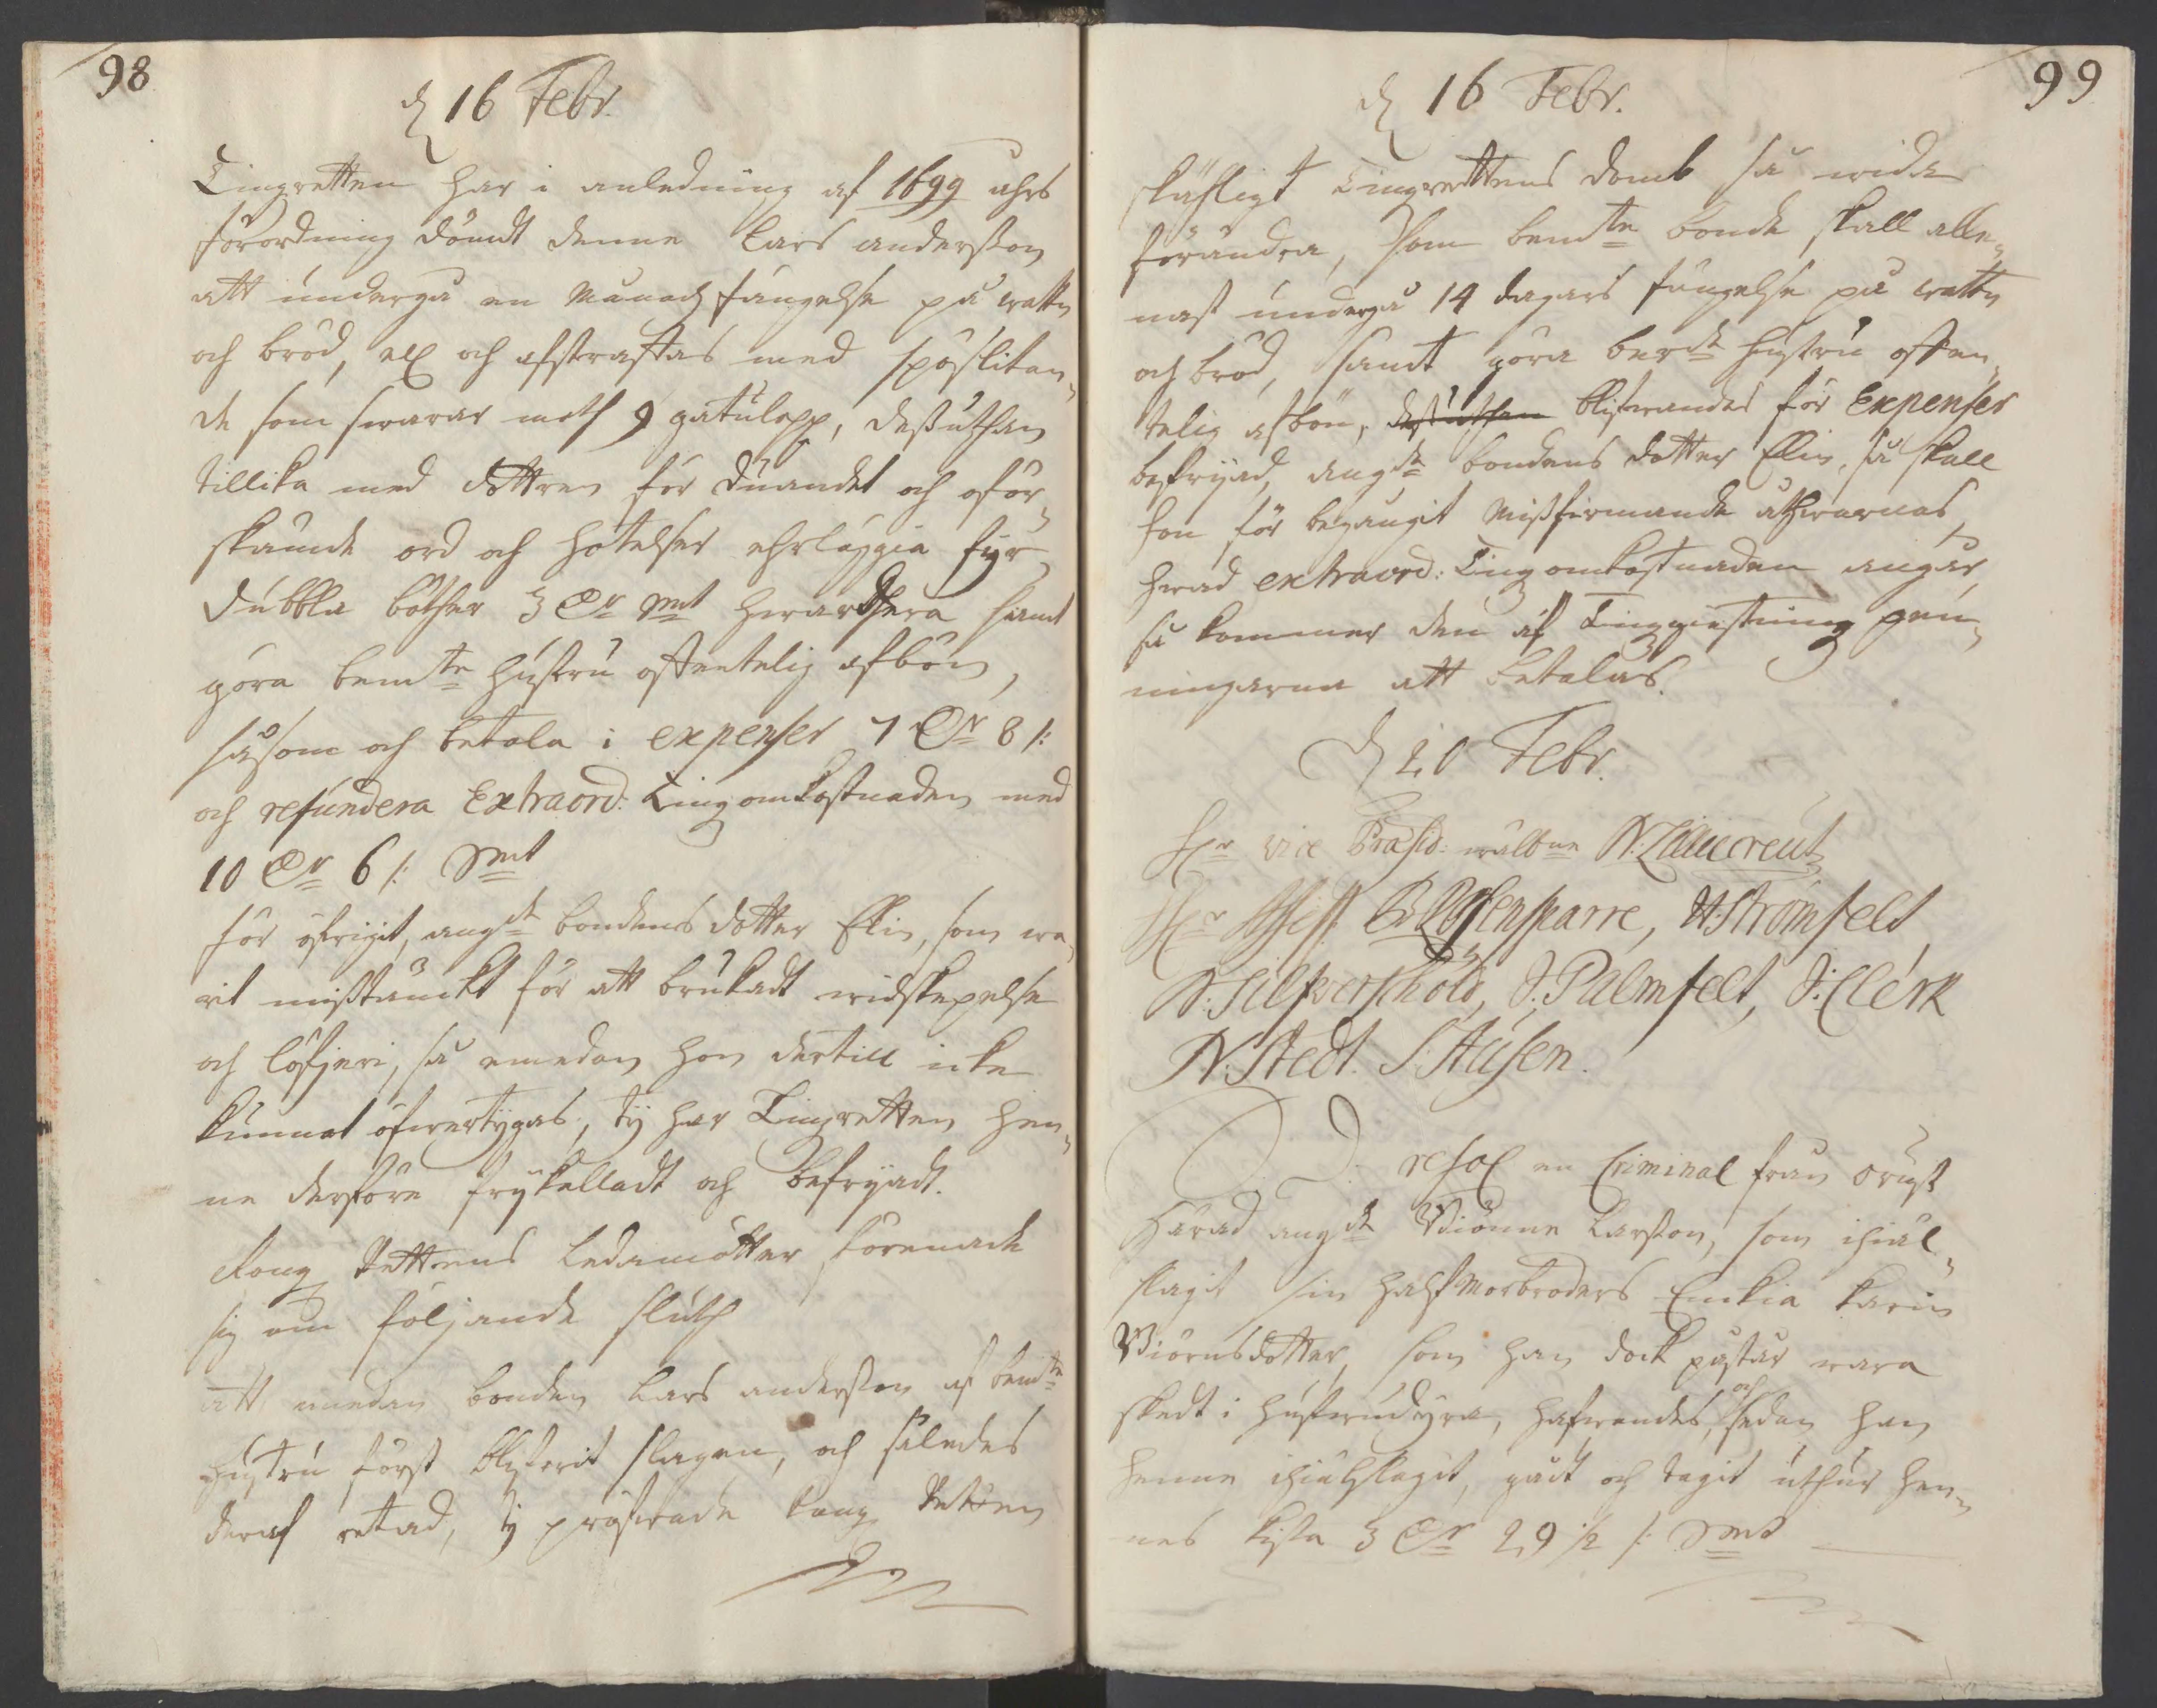

Найдено строк: 9402


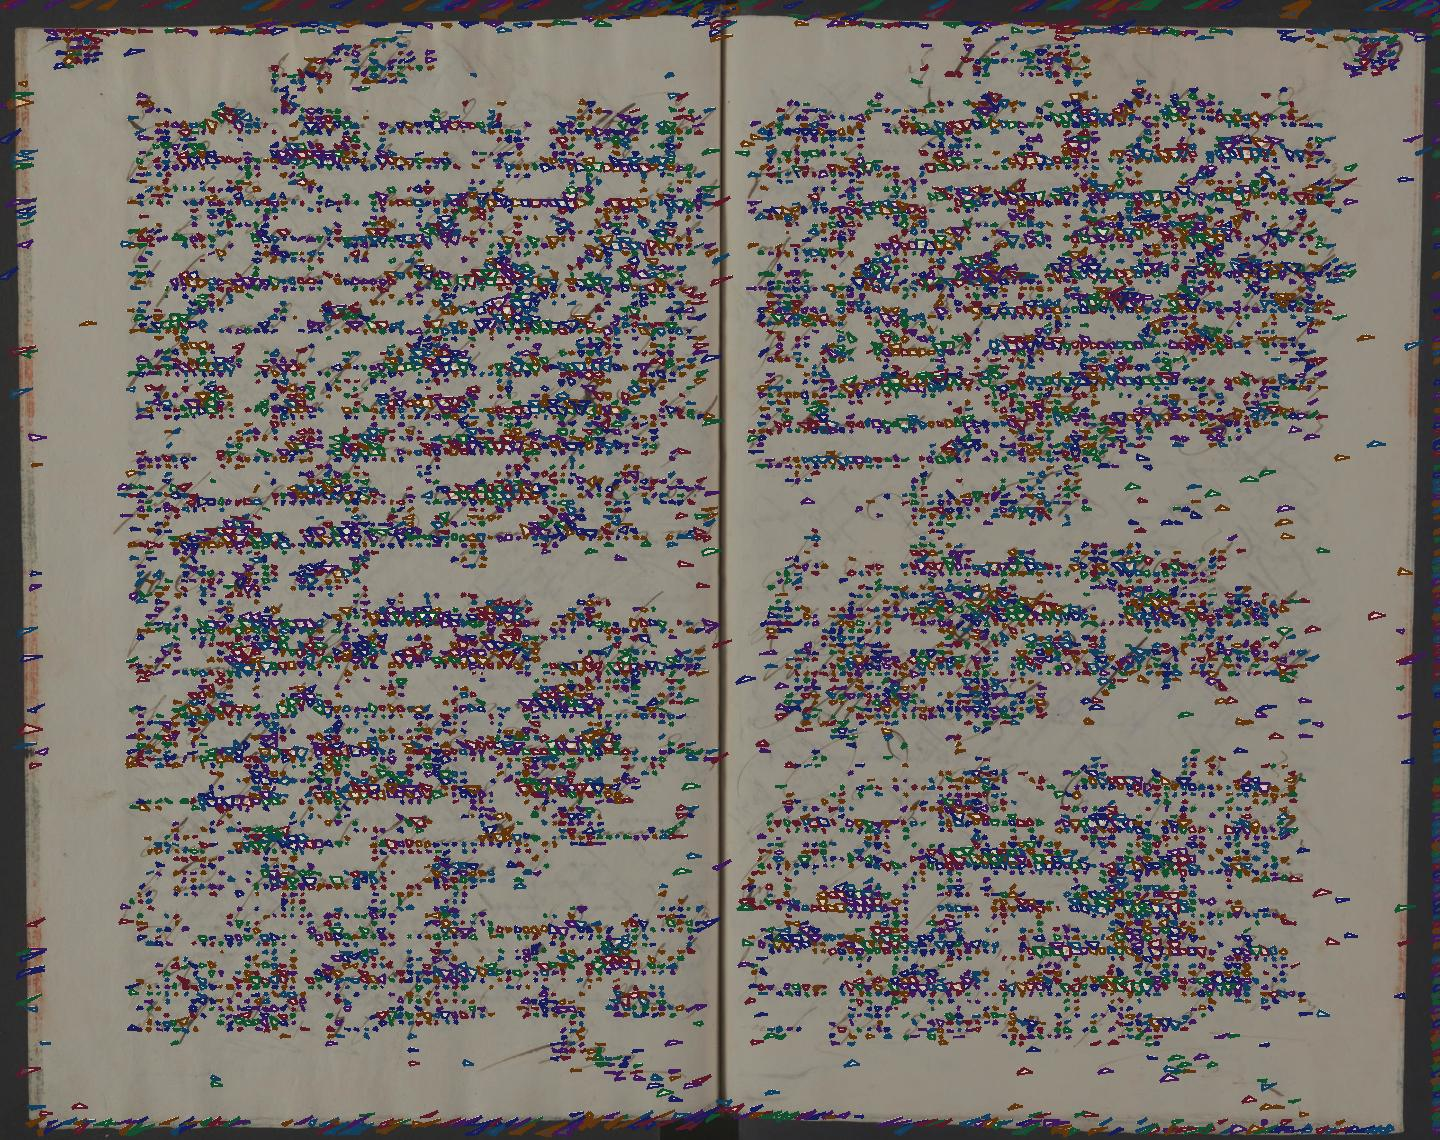

In [5]:
validation = json.loads((DATA_DIR / "val_coco.json").read_text(encoding="utf-8"))
image_path = IMAGES_DIR / "val" / validation["images"][0]["file_name"]
image = Image.open(image_path).convert("RGB")
preview = image.copy()
preview.thumbnail((1440, 1440))
display(preview)
page = detector.predict(image)
print(f"Найдено строк: {len(page.children)}")
display(visualize_page(image, page, numbers_levels=[], max_size=1440, upscale=True))
